<a href="https://colab.research.google.com/github/HoangMinhne0903/6451071046_Lab1_Phan_1/blob/main/6451071046_LAB1_Phan1_Bai2_Trang28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phần 1 - Bài 2 (Trang 28): Khảo sát & Tiền xử lý dữ liệu Bank Marketing


**Câu 1:**

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu (dùng separator dấu chấm phẩy vì bank marketing dùng ;)
df = pd.read_csv("bank.csv", sep=";")

print("=" * 60)
print("1. KHÁM PHÁ DỮ LIỆU TỔNG QUAN")
print("=" * 60)
print("\n- Kích thước dữ liệu (Số dòng x Số cột):", df.shape)
print("\n- 5 dòng đầu tiên:")
print(df.head())
print("\n- Thông tin kiểu dữ liệu và số non-null:")
print(df.info())
print("\n- Thống kê mô tả thuộc tính số:")
print(df.describe())
print("\n- Thống kê mô tả thuộc tính phân loại:")
print(df.describe(include=["O"]))


Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
1. KHÁM PHÁ DỮ LIỆU TỔNG QUAN

- Kích thước dữ liệu (Số dòng x Số cột): (4521, 17)

- 5 dòng đầu tiên:
   age          job  marital  education default  balance housing loan  \
0   30   unemployed  married    primary      no     1787      no   no   
1   33     services  married  secondary      no     4789     yes  yes   
2   35   management   single   tertiary      no     1350     yes   no   
3   30   management  married   tertiary      no     1476     yes  yes   
4   59  blue-collar  married  secondary      no        0     yes   no   

    contact  day month  duration  campaign  pdays  previous poutcome   y  
0  cellular   19   oct        79         1     -1         0  unknown  no  
1  cellular   11   may       220         1    339         4  failure  no  
2  cellular   16   apr       185         1    330         1  failure  no  
3   unknown    3   jun       199         4     -1         0  unknown  no  
4   unknown    5   may       226

**Câu 2:**

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# 2. PHÂN TÍCH GIÁ TRỊ RỖNG
print("=" * 60)
print("2. PHÂN TÍCH GIÁ TRỊ RỖNG")
print("=" * 60)
missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df)) * 100
missing_df = pd.DataFrame({
    "Số lượng rỗng": missing_count,
    "Tỉ lệ (%)": missing_percent.round(2)
})
print(missing_df[missing_df["Số lượng rỗng"] > 0] if missing_df["Số lượng rỗng"].sum() > 0 else "Không có giá trị rỗng!")


Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
2. PHÂN TÍCH GIÁ TRỊ RỖNG
Không có giá trị rỗng!


**Câu 3:**

Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
3. PHÂN TÍCH TỈ LỆ ĐĂNG KÝ GỬI TIỀN CÓ KỲ HẠN
y
no     4000
yes     521
Name: count, dtype: int64

Tỉ lệ:
y
no     88.48
yes    11.52
Name: proportion, dtype: float64


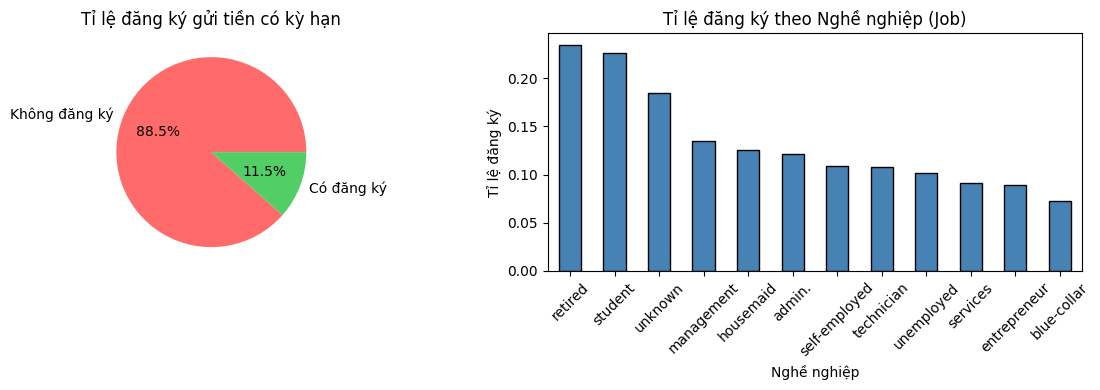

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# 3. PHÂN TÍCH TỈ LỆ ĐĂNG KÝ (target: y - Subscribe)
print("=" * 60)
print("3. PHÂN TÍCH TỈ LỆ ĐĂNG KÝ GỬI TIỀN CÓ KỲ HẠN")
print("=" * 60)
print(df["y"].value_counts())
print("\nTỉ lệ:")
print(df["y"].value_counts(normalize=True).round(4) * 100)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Pie chart
df["y"].value_counts().plot(kind="pie", autopct="%1.1f%%", ax=axes[0],
                             labels=["Không đăng ký", "Có đăng ký"],
                             colors=["#FF6B6B", "#51CF66"])
axes[0].set_title("Tỉ lệ đăng ký gửi tiền có kỳ hạn")
axes[0].set_ylabel("")

# Bar chart theo job
df.groupby("job")["y"].apply(lambda x: (x == "yes").mean()).sort_values(ascending=False).plot(
    kind="bar", ax=axes[1], color="steelblue", edgecolor="black")
axes[1].set_title("Tỉ lệ đăng ký theo Nghề nghiệp (Job)")
axes[1].set_xlabel("Nghề nghiệp")
axes[1].set_ylabel("Tỉ lệ đăng ký")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


**Câu 4:**

Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046
4. PHÂN TÍCH MỐI QUAN HỆ GIỮA CÁC THUỘC TÍNH VÀ KHẢ NĂNG ĐĂNG KÝ


/tmp/ipykernel_490/2613677995.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x="y", y="duration", data=df, ax=axes[0][0], palette="Set2")


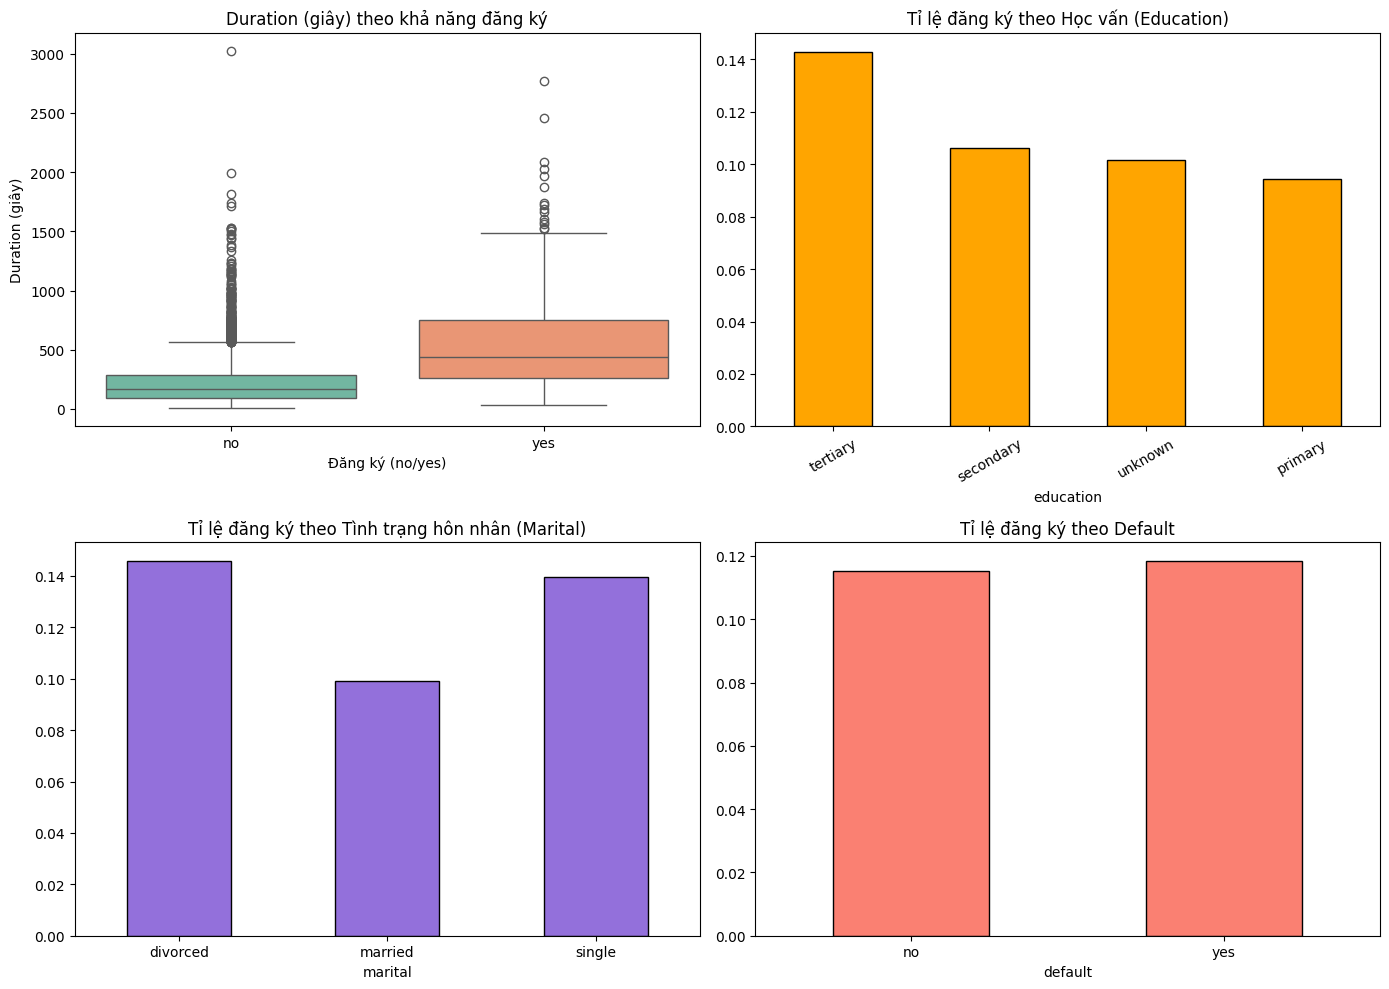

In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# 4. PHÂN TÍCH THEO TỪNG THUỘC TÍNH
print("=" * 60)
print("4. PHÂN TÍCH MỐI QUAN HỆ GIỮA CÁC THUỘC TÍNH VÀ KHẢ NĂNG ĐĂNG KÝ")
print("=" * 60)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Duration vs Subscribe
sns.boxplot(x="y", y="duration", data=df, ax=axes[0][0], palette="Set2")
axes[0][0].set_title("Duration (giây) theo khả năng đăng ký")
axes[0][0].set_xlabel("Đăng ký (no/yes)")
axes[0][0].set_ylabel("Duration (giây)")

# Education
df.groupby("education")["y"].apply(lambda x: (x == "yes").mean()).sort_values(ascending=False).plot(
    kind="bar", ax=axes[0][1], color="orange", edgecolor="black")
axes[0][1].set_title("Tỉ lệ đăng ký theo Học vấn (Education)")
axes[0][1].tick_params(axis="x", rotation=30)

# Marital
df.groupby("marital")["y"].apply(lambda x: (x == "yes").mean()).plot(
    kind="bar", ax=axes[1][0], color="mediumpurple", edgecolor="black")
axes[1][0].set_title("Tỉ lệ đăng ký theo Tình trạng hôn nhân (Marital)")
axes[1][0].tick_params(axis="x", rotation=0)

# Default
df.groupby("default")["y"].apply(lambda x: (x == "yes").mean()).plot(
    kind="bar", ax=axes[1][1], color="salmon", edgecolor="black")
axes[1][1].set_title("Tỉ lệ đăng ký theo Default")
axes[1][1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


In [ ]:
print("Họ và tên: Nguyễn Lê Hoàng Minh - MSSV: 6451071046")

# 5. TIỀN XỬ LÝ
print("=" * 60)
print("5. TIỀN XỬ LÝ DỮ LIỆU BANK MARKETING")
print("=" * 60)

df_clean = df.copy()

# 5a. Chuyển cột target y thành số
df_clean["subscribe"] = df_clean["y"].map({"yes": 1, "no": 0})

# 5b. Mã hóa các thuộc tính phân loại (One-hot encoding)
cat_cols = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "poutcome"]
df_encoded = pd.get_dummies(df_clean, columns=cat_cols, drop_first=True)
df_encoded.drop(columns=["y"], inplace=True)

print("Các cột sau khi mã hóa:", df_encoded.columns.tolist())
print("\nKích thước sau tiền xử lý:", df_encoded.shape)
print("\n10 dòng đầu:")
print(df_encoded.head(10))

print("\n Tiền xử lý hoàn tất!")
